# Can cheap gas sensors stand in for a reference CO analyser?
**Dataset:** UCI Air Quality (De Vito et al., 2008) · **Target:** reference CO, `CO(GT)` in mg/m³ · **Split:** chronological (60 / 20 / 20 %)

This notebook walks through the project step by step by calling the functions in `src/`. Run all cells from the top.
The last section regenerates every figure and table with `python -m src.run_pipeline`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))                       # lets the notebook import the src/ package
import pandas as pd
from IPython.display import Image, display
from src import config as C, data, features, models, evaluate, run_pipeline
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20)
print("project root:", ROOT, "| random seed:", C.SEED)

project root: /tmp/airquality_project | random seed: 42


## 1. Load the file and audit it
The CSV uses `;` separators and decimal commas, has 2 empty columns and many blank rows. `-200` means *missing*.

In [2]:
df_coded, load_info = data.load_raw()
missing_tbl, audit_rep, _ = data.audit(df_coded)
print(load_info)
print({k: v for k, v in audit_rep.items() if k != "longest_identical_run_hours"})
missing_tbl.sort_values("pct_missing", ascending=False)

{'raw_rows': 9471, 'raw_cols': 17, 'empty_columns_dropped': 2, 'blank_rows_dropped': 114, 'rows': 9357, 'cols': 15}
{'n_rows': 9357, 'date_min': '2004-03-10 18:00:00', 'date_max': '2005-04-04 14:00:00', 'sorted_in_time': True, 'duplicate_rows': 0, 'duplicate_timestamps': 0, 'expected_hourly_timestamps': 9357, 'missing_timestamps': 0, 'rows_all_sensors_missing': 366, 'rh_outside_0_100': 0, 'negative_sensor_values': 0, 'negative_reference_values': 0, 'temperature_min_max': [-1.9, 44.6]}


,n_missing,pct_missing
NMHC(GT),8443,90.23
CO(GT),1683,17.99
NO2(GT),1642,17.55
NOx(GT),1639,17.52
PT08.S1(CO),366,3.91
PT08.S2(NMHC),366,3.91
C6H6(GT),366,3.91
PT08.S3(NOx),366,3.91
PT08.S4(NO2),366,3.91
PT08.S5(O3),366,3.91


## 2. Cleaning decisions
* `NMHC(GT)` is ~90 % missing → not used.
* Rows where all sensors are missing (device outage) → dropped; nothing to impute from.
* Rows where the target `CO(GT)` is missing → dropped; we never invent reference values.
* Outliers are **kept**: high-CO hours are real pollution episodes, exactly what we want to predict.

In [3]:
table, drop_counts, df_nan = data.build_model_table(df_coded)
print(drop_counts)
bz = df_nan[["PT08.S2(NMHC)", "C6H6(GT)"]].dropna()
import numpy as np
c = np.polyfit(bz.iloc[:, 0], bz.iloc[:, 1], 2)
r = bz.iloc[:, 1] - np.polyval(c, bz.iloc[:, 0])
print("Benzene vs ONE sensor, quadratic fit R2 = %.4f, RMSE = %.3f ug/m3  -> not an independent reference, so benzene is not our target"
      % (1 - (r**2).sum() / ((bz.iloc[:, 1] - bz.iloc[:, 1].mean())**2).sum(), np.sqrt((r**2).mean())))

{'rows_before': 9357, 'dropped_input_outage': 366, 'dropped_target_missing_only': 1647, 'rows_after': 7344}
Benzene vs ONE sensor, quadratic fit R2 = 0.9999, RMSE = 0.079 ug/m3  -> not an independent reference, so benzene is not our target


## 3. Feature engineering and the chronological split
Time features come only from the timestamp. The split is never shuffled: the model is always tested on the *future*.

In [4]:
table = features.add_time_features(table)
train, val, test = data.split_chronological(table)
for name, part in (("train", train), ("validation", val), ("test", test)):
    print(f"{name:10s} {len(part):5d} rows  {part.datetime.min()}  ->  {part.datetime.max()}")
table[["datetime", C.TARGET, "PT08.S1(CO)", "T", "RH", "hour_sin", "hour_cos", "is_weekend"]].head()

train       4406 rows  2004-03-10 18:00:00  ->  2004-11-15 10:00:00
validation  1469 rows  2004-11-15 11:00:00  ->  2005-01-28 11:00:00
test        1469 rows  2005-01-28 12:00:00  ->  2005-04-04 14:00:00


,datetime,CO(GT),PT08.S1(CO),T,RH,hour_sin,hour_cos,is_weekend
0,2004-03-10 18:00:00,2.6,1360.0,13.6,48.9,-1.000000,-1.836970e-16,0
1,2004-03-10 19:00:00,2.0,1292.0,13.3,47.7,-0.965926,2.588190e-01,0
2,2004-03-10 20:00:00,2.2,1402.0,11.9,54.0,-0.866025,5.000000e-01,0
3,2004-03-10 21:00:00,2.2,1376.0,11.0,60.0,-0.707107,7.071068e-01,0
4,2004-03-10 22:00:00,1.6,1272.0,11.2,59.6,-0.500000,8.660254e-01,0


## 4. A first model by hand: baseline vs simple linear regression
The baseline always predicts the training mean (the lecture's *naive guesser*).

In [5]:
specs = models.build_models()
for name in ["Baseline: training mean", "M1 Simple linear (S1 only)", "M3 Multiple linear (+time features)"]:
    est, feats, status = specs[name]
    est.fit(train[feats], train[C.TARGET])
    m = evaluate.regression_metrics(val[C.TARGET], est.predict(val[feats]))
    print(f"{name:38s} validation  MAE {m['MAE']:.3f}  RMSE {m['RMSE']:.3f}  R2 {m['R2']:.3f}")

Baseline: training mean                validation  MAE 1.299  RMSE 1.785  R2 -0.084
M1 Simple linear (S1 only)             validation  MAE 0.630  RMSE 0.921  R2 0.711
M3 Multiple linear (+time features)    validation  MAE 0.552  RMSE 0.786  R2 0.790


## 5. Run the complete pipeline
This regenerates every table, figure and `outputs/results.json` (about 5 seconds).

In [6]:
R = run_pipeline.main()


=== MODEL COMPARISON (RMSE, MAE, R2) ===
                                     CV_RMSE_train  RMSE_train  RMSE_val  RMSE_test  MAE_val  MAE_test  R2_val  R2_test
model                                                                                                                  
Baseline: training mean                      1.344       1.349     1.785      1.320    1.299     1.068  -0.084   -0.030
M1 Simple linear (S1 only)                   0.615       0.578     0.921      0.721    0.630     0.550   0.711    0.693
M2 Multiple linear (8 inputs)                0.403       0.349     0.794      0.484    0.554     0.344   0.785    0.862
M3 Multiple linear (+time features)          0.406       0.341     0.786      0.483    0.552     0.352   0.790    0.862
M4 M3 on log(1+CO)                           0.401       0.320     0.828      0.451    0.483     0.284   0.767    0.880
M5 Polynomial + Ridge (tuned)                0.361       0.257     0.777      0.446    0.511     0.307   0.795    0.88

## 6. Exploratory data analysis
Core EDA uses development data only (train + validation). Three figures are full-dataset *descriptive* analyses that do not influence modelling: `eda_01` (missingness), `eda_06` (monthly trend) and `eda_08` (benzene validity check).

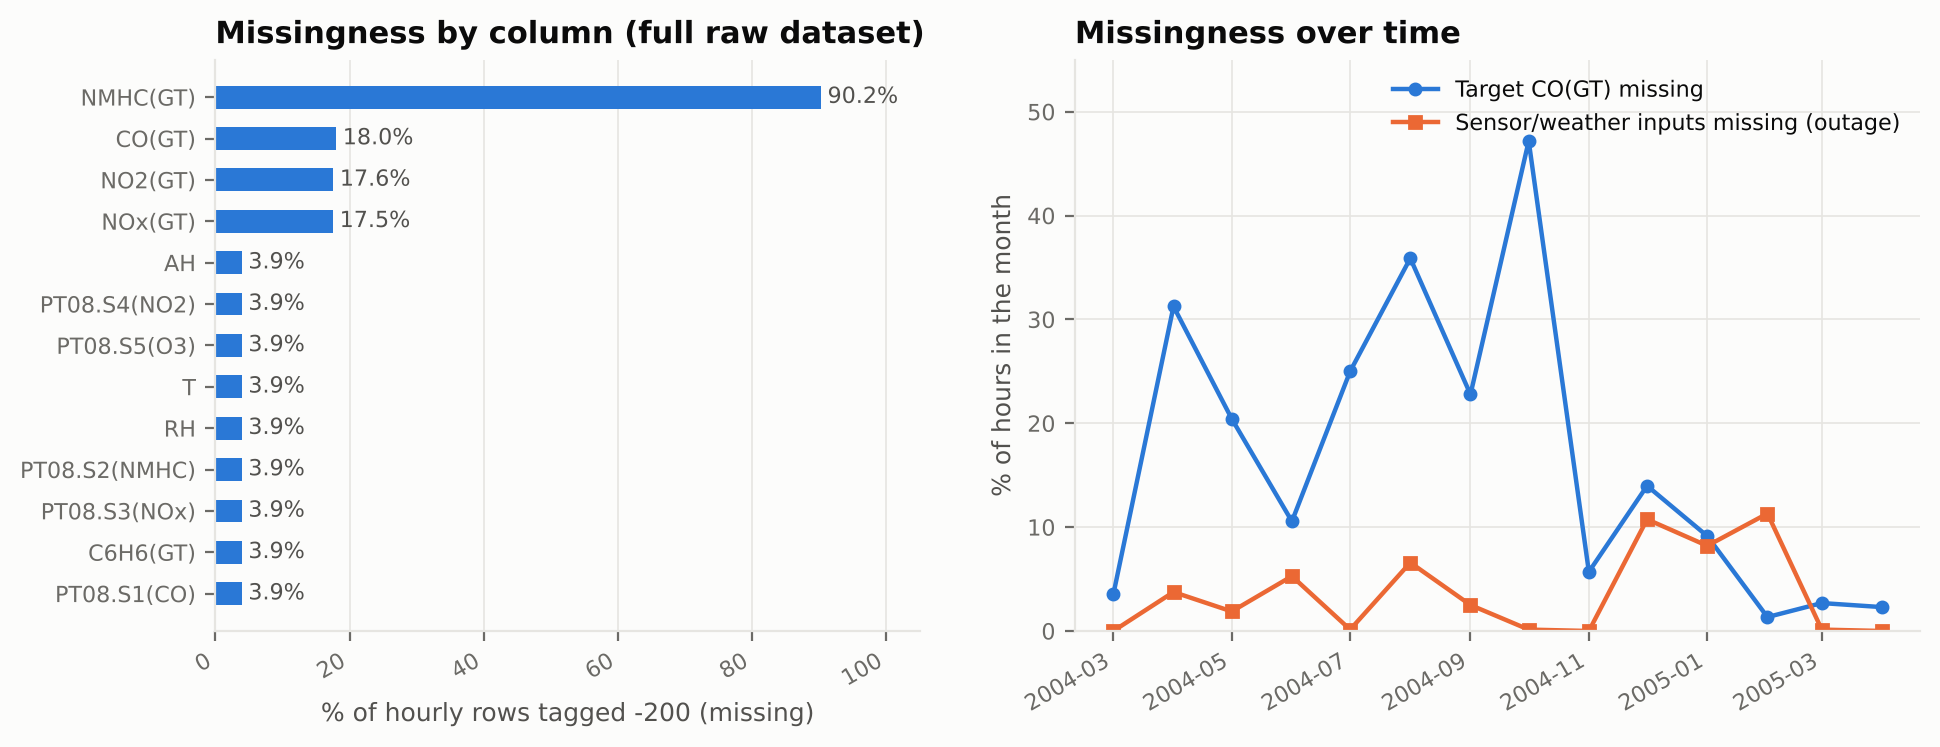

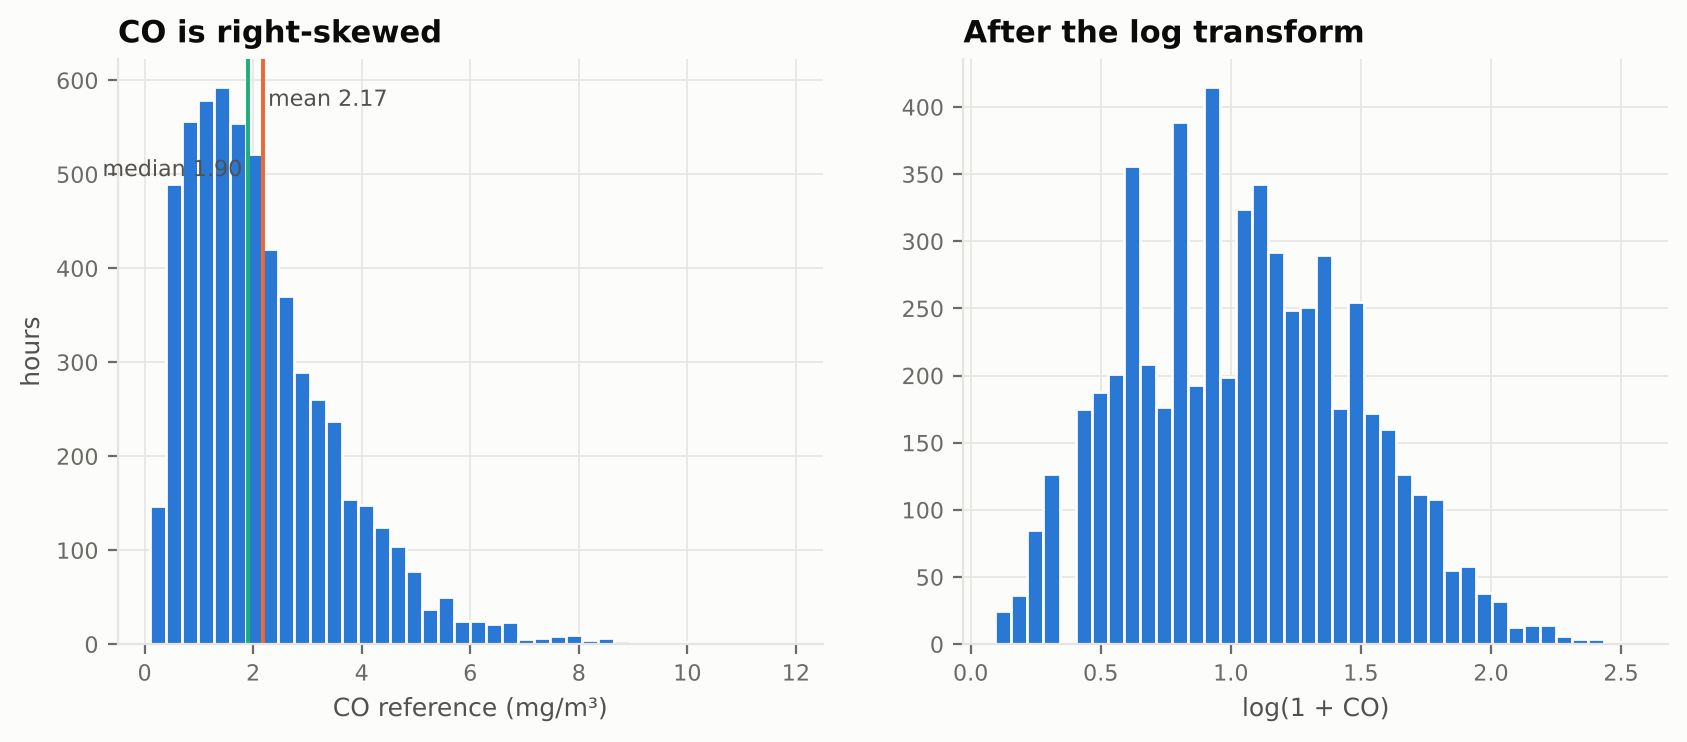

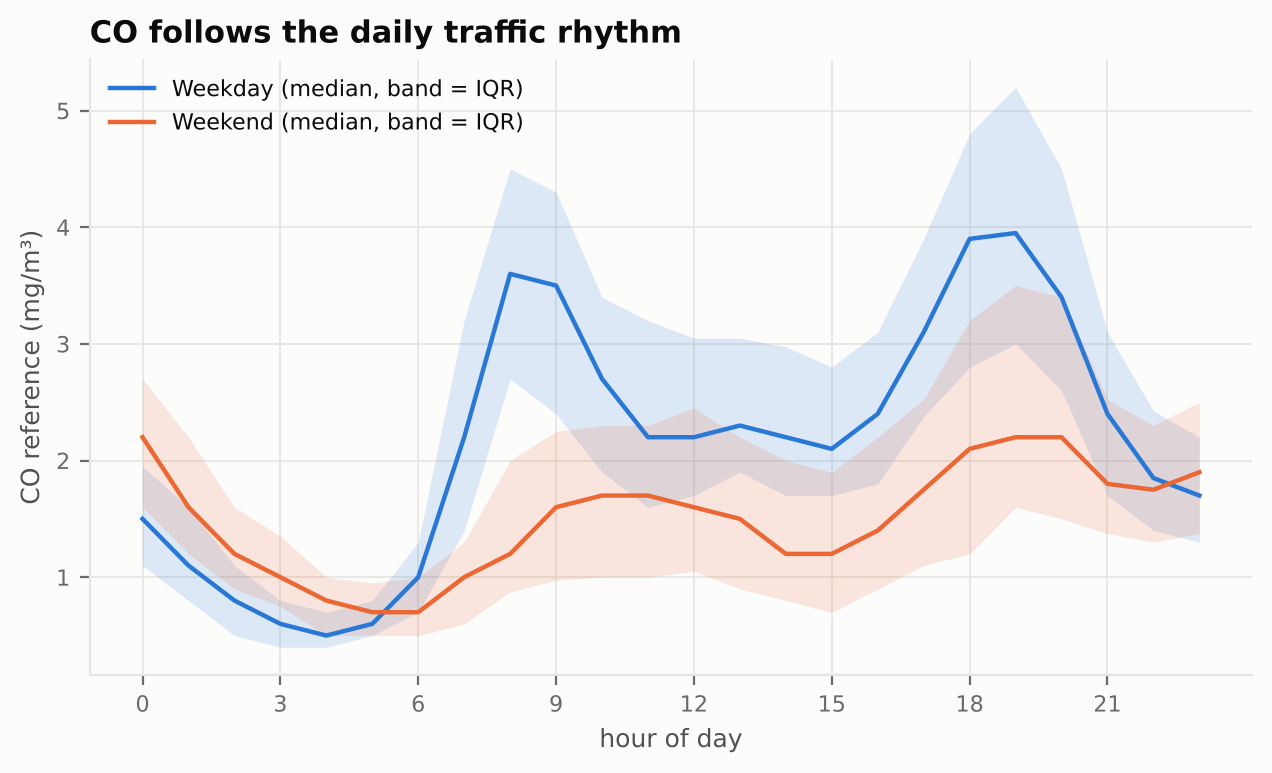

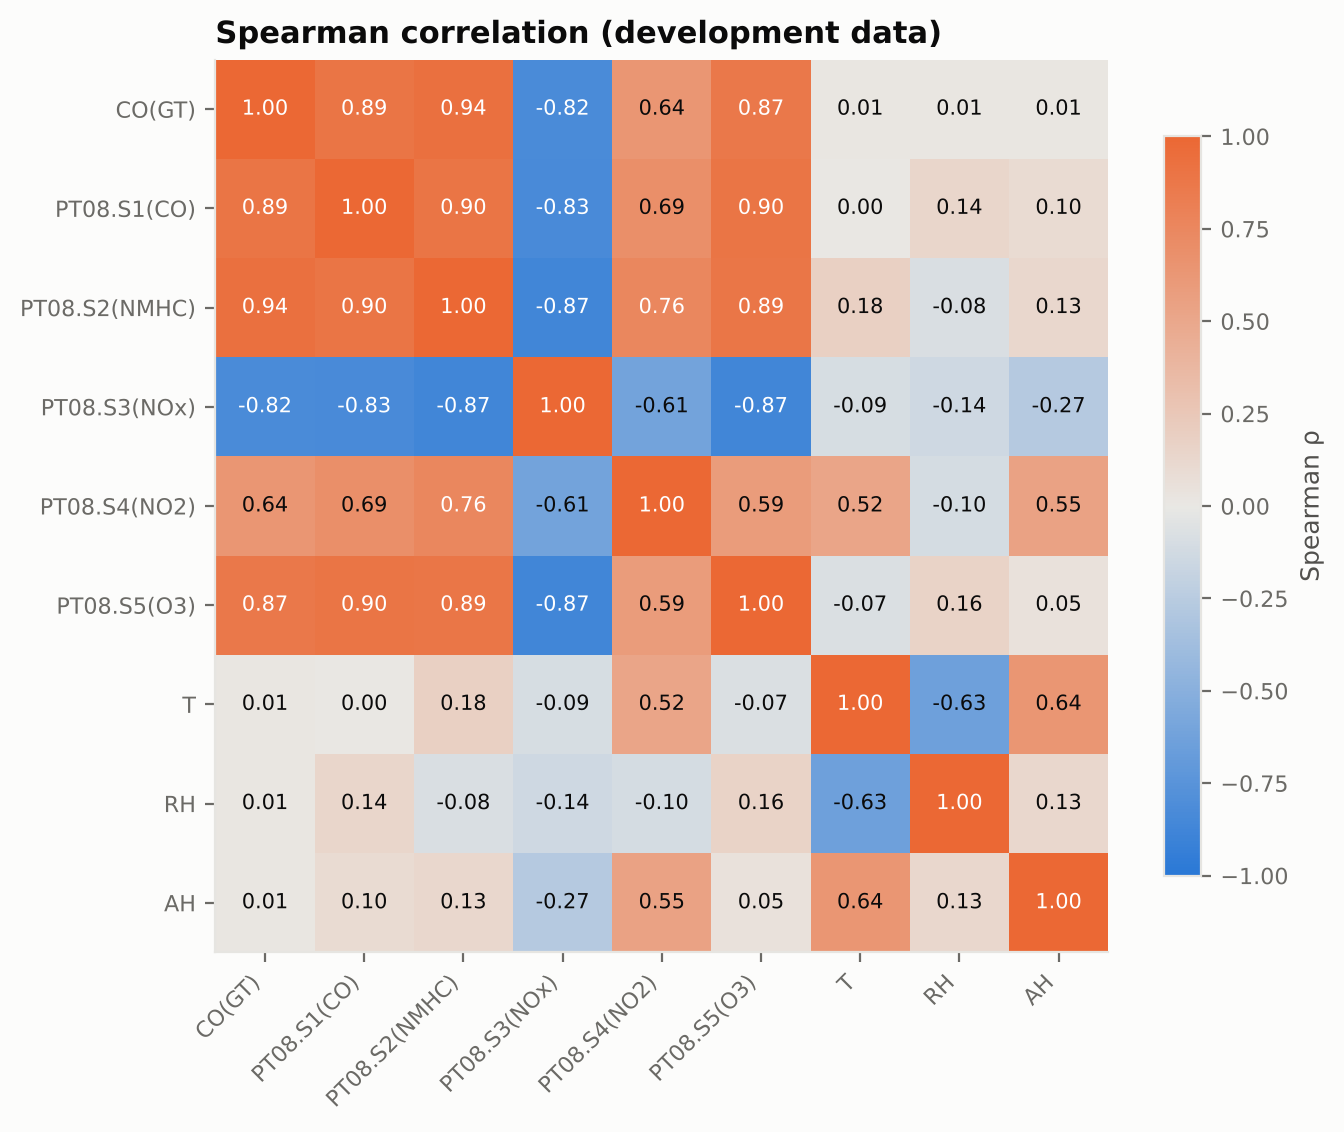

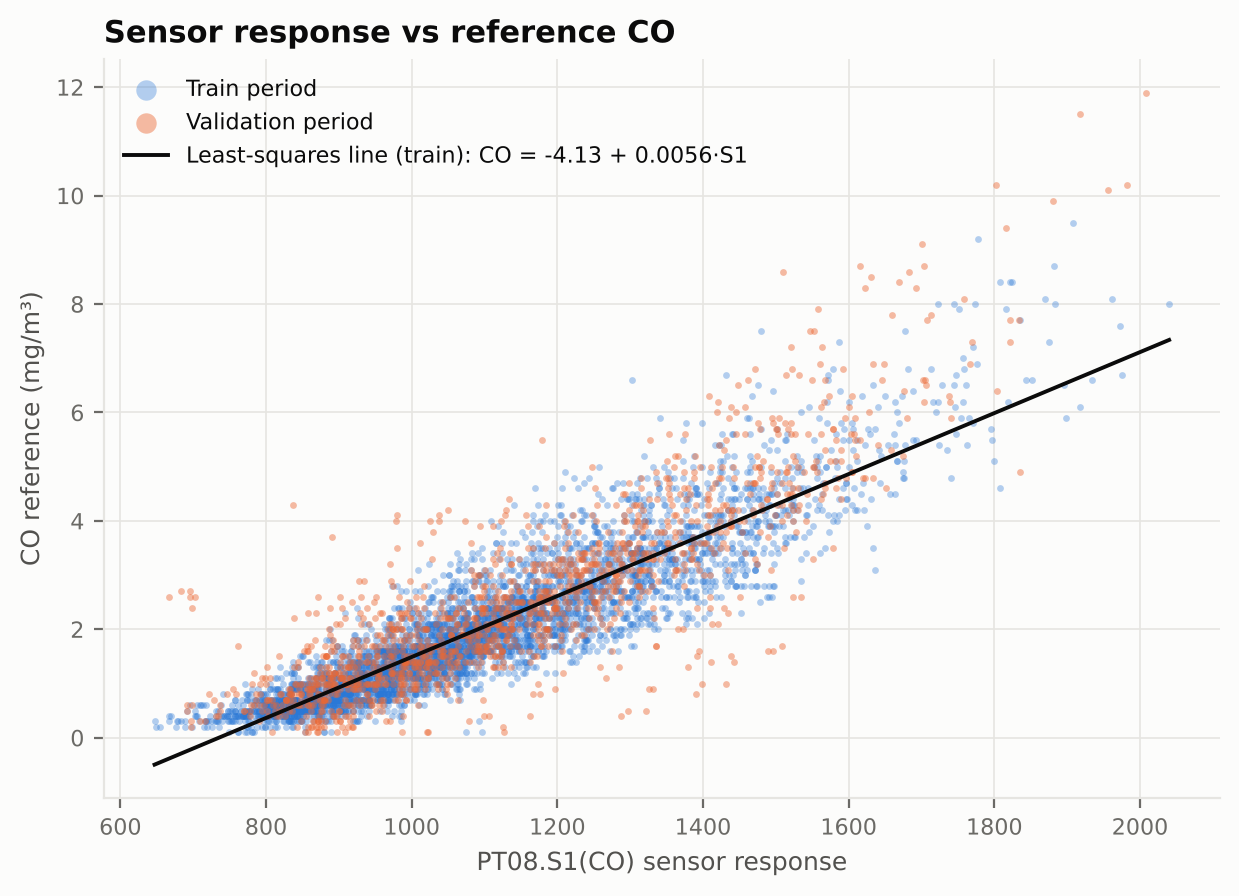

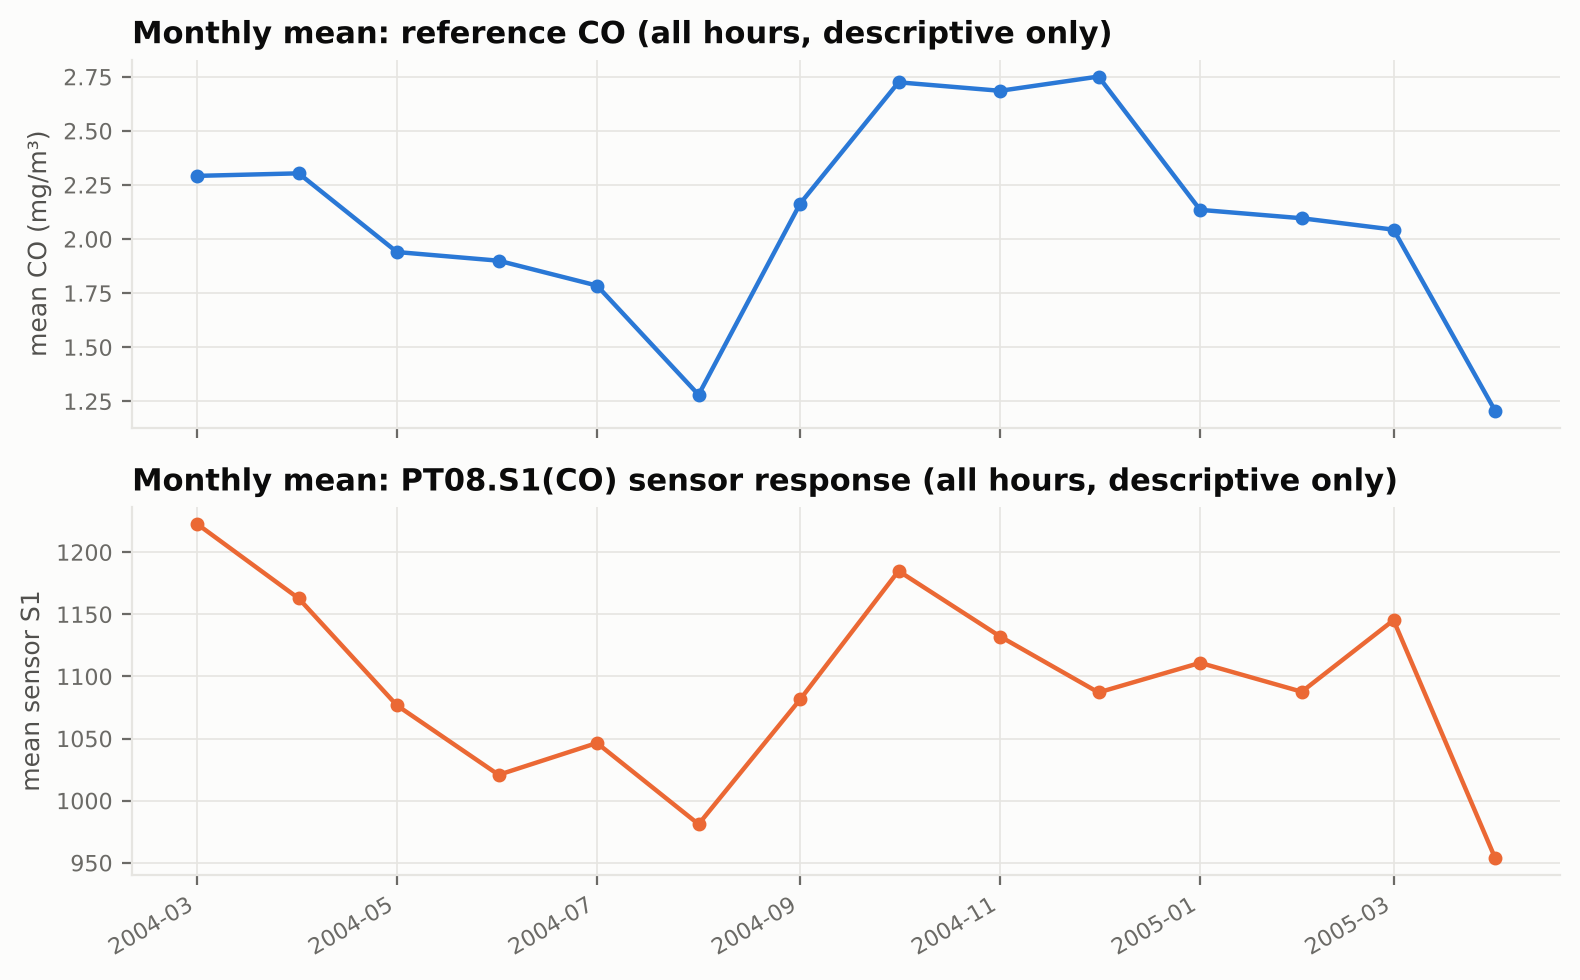

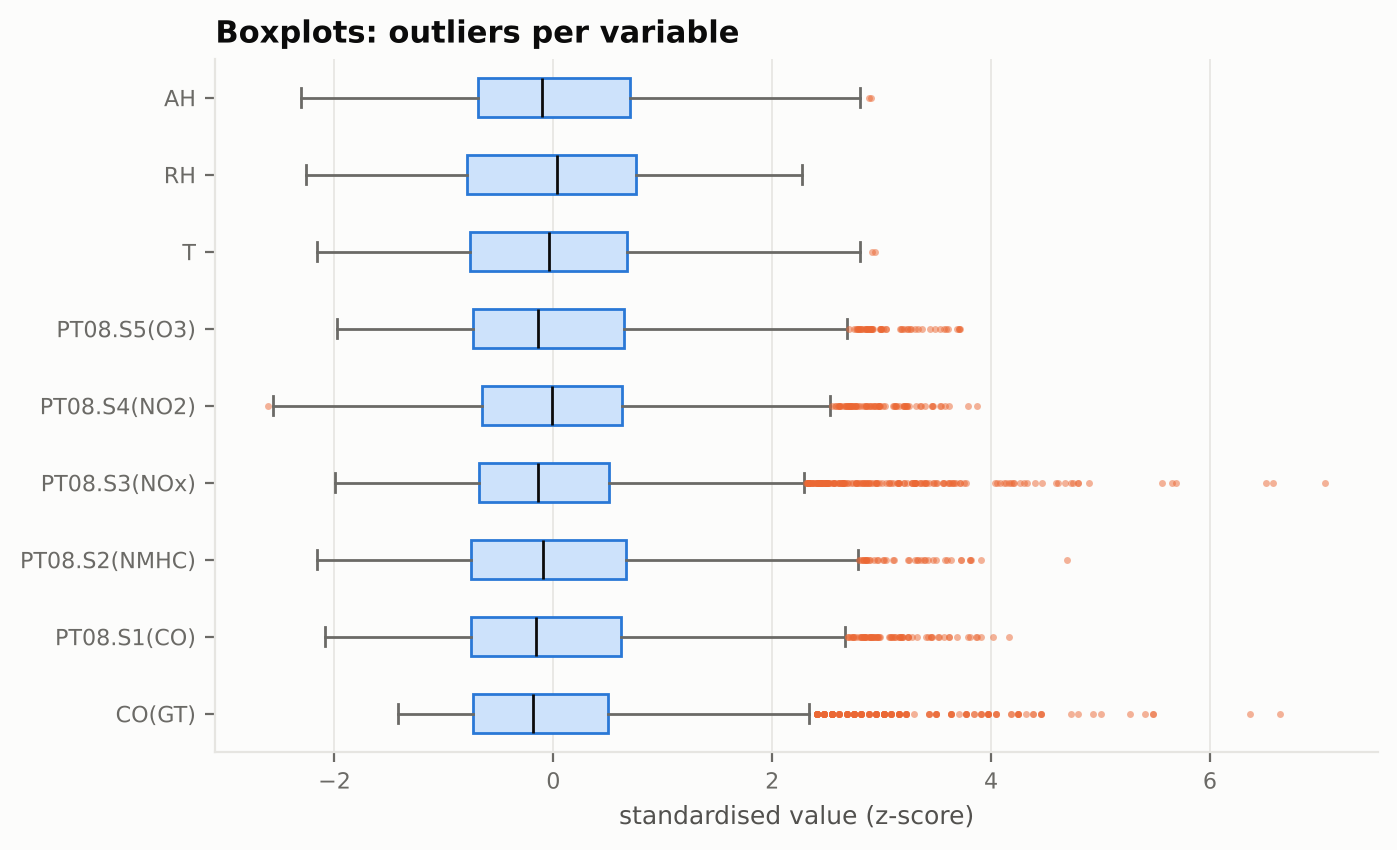

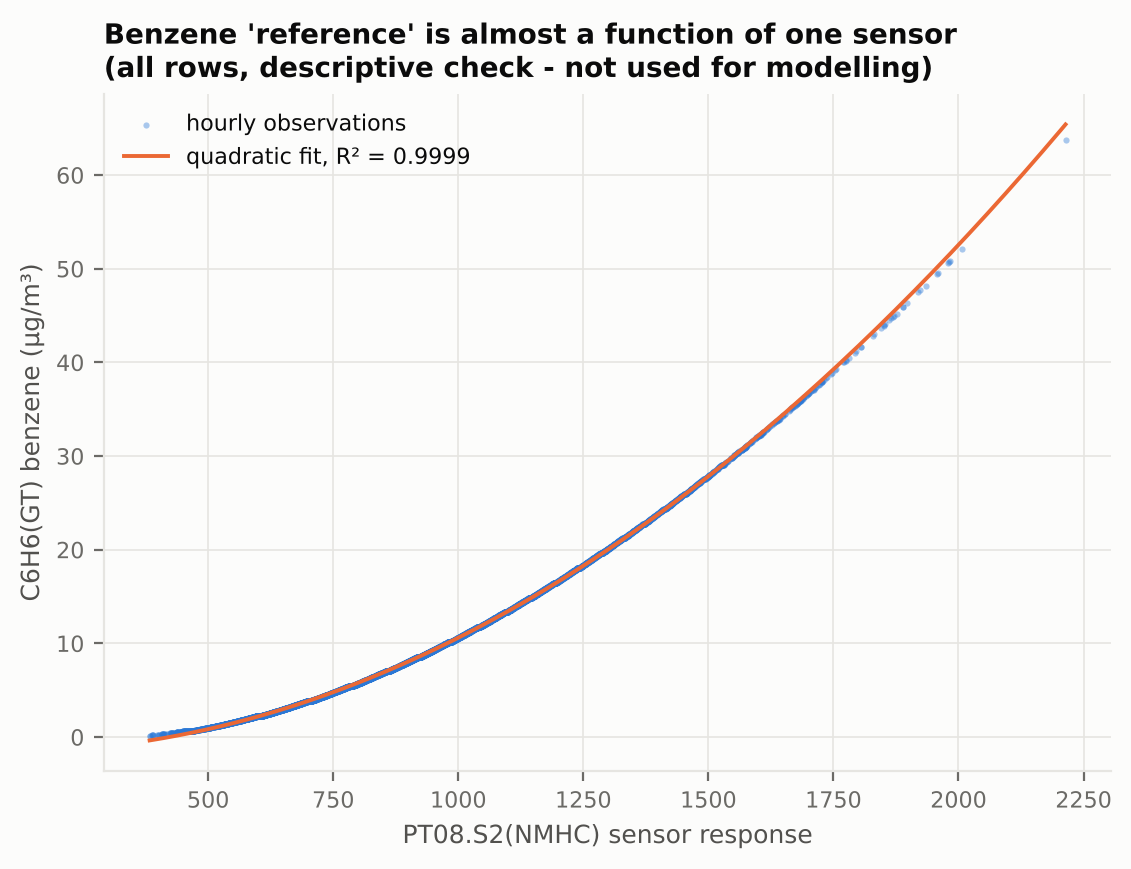

In [7]:
for f in ["eda_01_missingness", "eda_02_target_distribution", "eda_03_hourly_pattern", "eda_04_correlation",
          "eda_05_sensor_vs_target", "eda_06_monthly_trend", "eda_07_outliers", "eda_08_benzene_validity"]:
    display(Image(str(C.FIG_DIR / f"{f}.png"), width=640))

## 7. Model comparison (validation, then the test set once)

,status,CV_RMSE_train,RMSE_train,RMSE_val,RMSE_test,MAE_val,MAE_test,R2_val,R2_test
model,,,,,,,,,
Baseline: training mean,course (naive guesser),1.344,1.349,1.786,1.320,1.299,1.068,-0.084,-0.030
M1 Simple linear (S1 only),course,0.615,0.578,0.921,0.720,0.630,0.550,0.712,0.693
M2 Multiple linear (8 inputs),extension of course,0.403,0.349,0.794,0.484,0.554,0.344,0.786,0.862
M3 Multiple linear (+time features),extension of course,0.406,0.341,0.786,0.483,0.552,0.352,0.790,0.862
M4 M3 on log(1+CO),course (log transform) + extension,0.401,0.320,0.828,0.451,0.483,0.284,0.767,0.880
M5 Polynomial + Ridge (tuned),additional,0.361,0.258,0.777,0.446,0.511,0.307,0.795,0.882


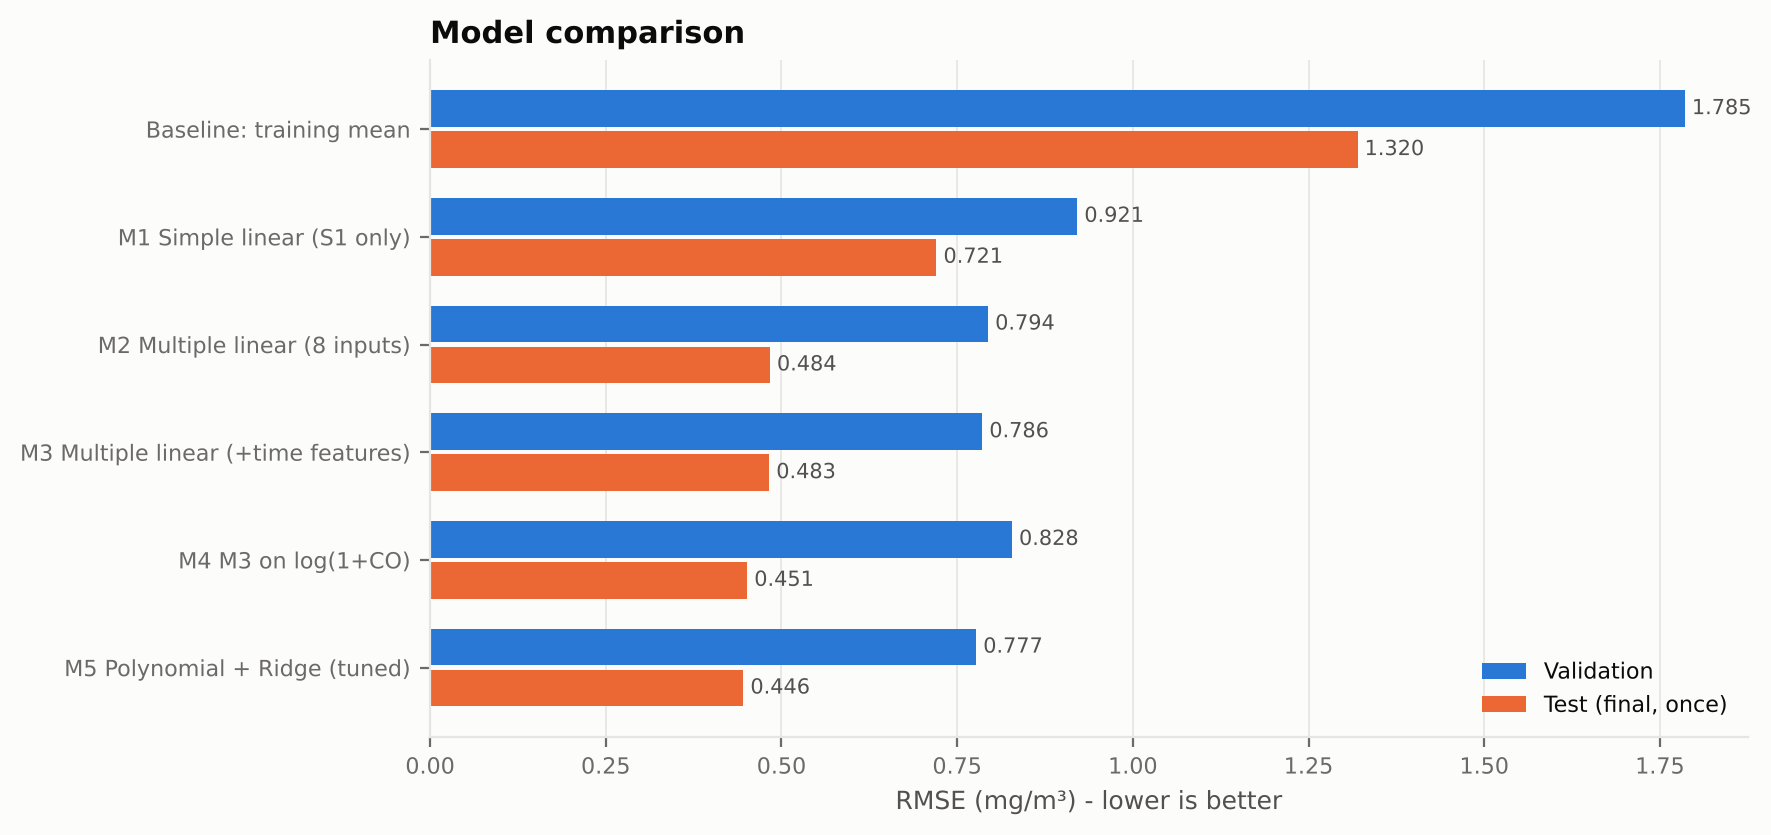

Best on validation RMSE: M5 Polynomial + Ridge (tuned) {'poly__degree': 2, 'ridge__alpha': 100}


In [8]:
comp = pd.read_csv(C.TABLE_DIR / "04_model_comparison.csv", index_col=0)
display(comp[["status", "CV_RMSE_train", "RMSE_train", "RMSE_val", "RMSE_test", "MAE_val", "MAE_test", "R2_val", "R2_test"]].round(3))
display(Image(str(C.FIG_DIR / "res_01_model_comparison.png"), width=700))
print("Best on validation RMSE:", R["best_model_by_validation"], R["tuning"]["best_params"])

## 8. Error analysis

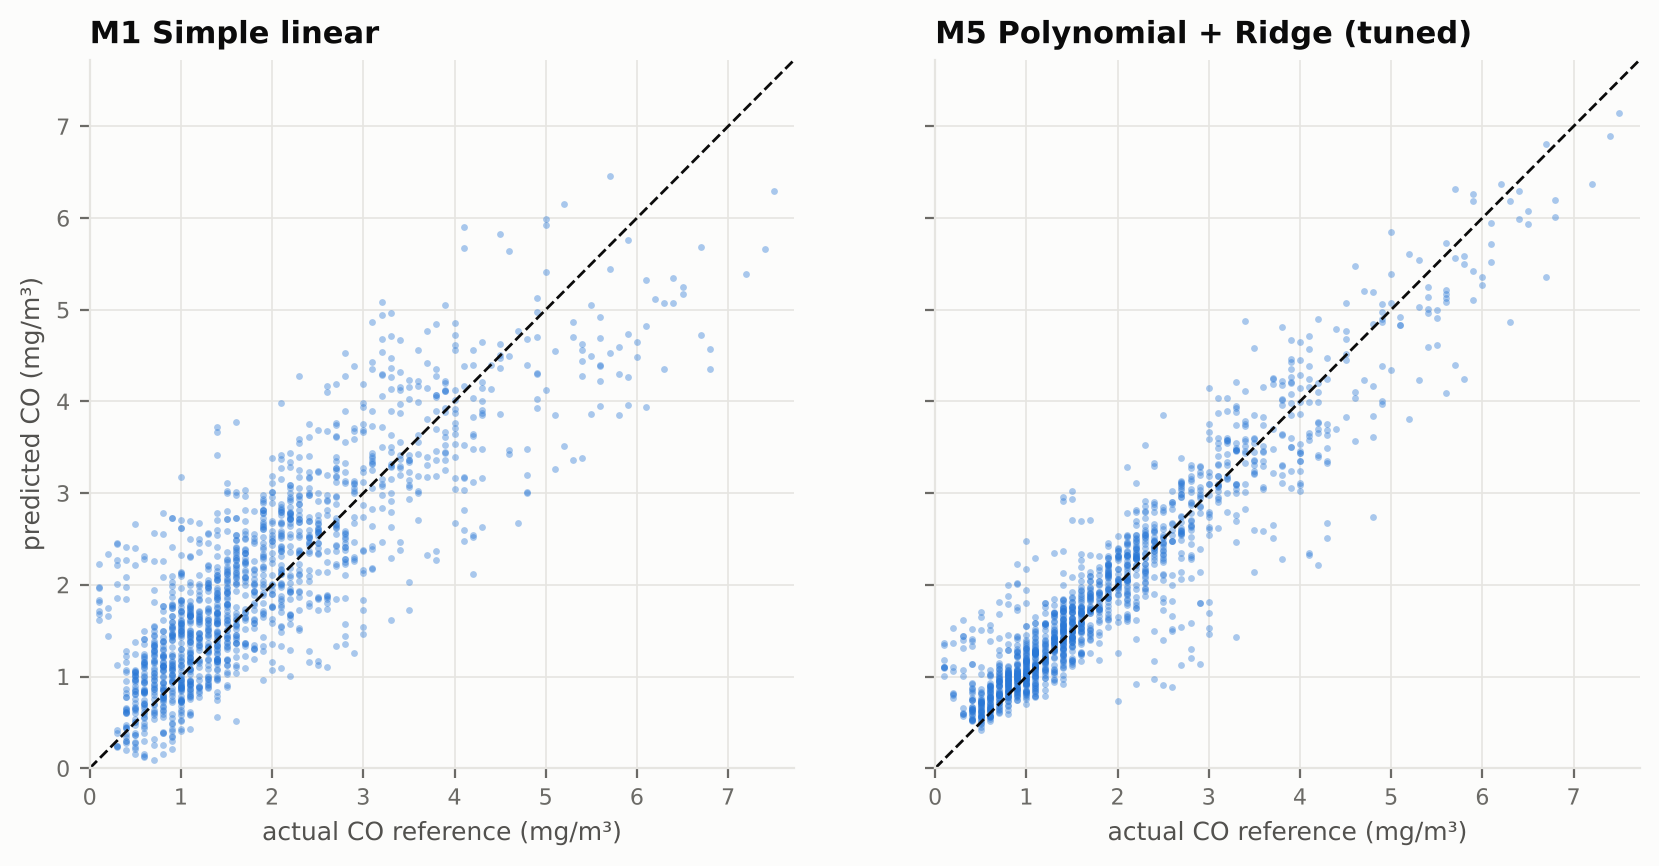

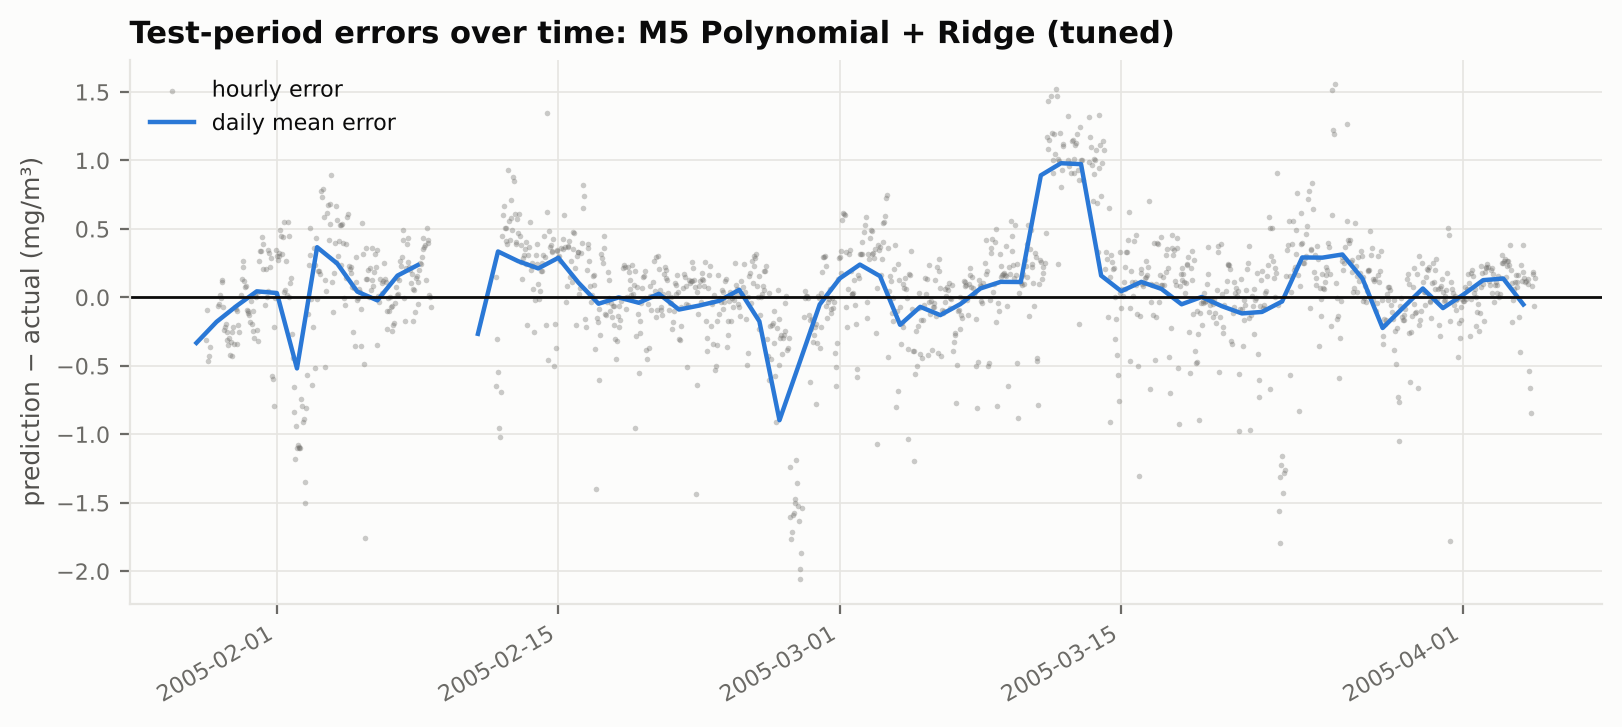

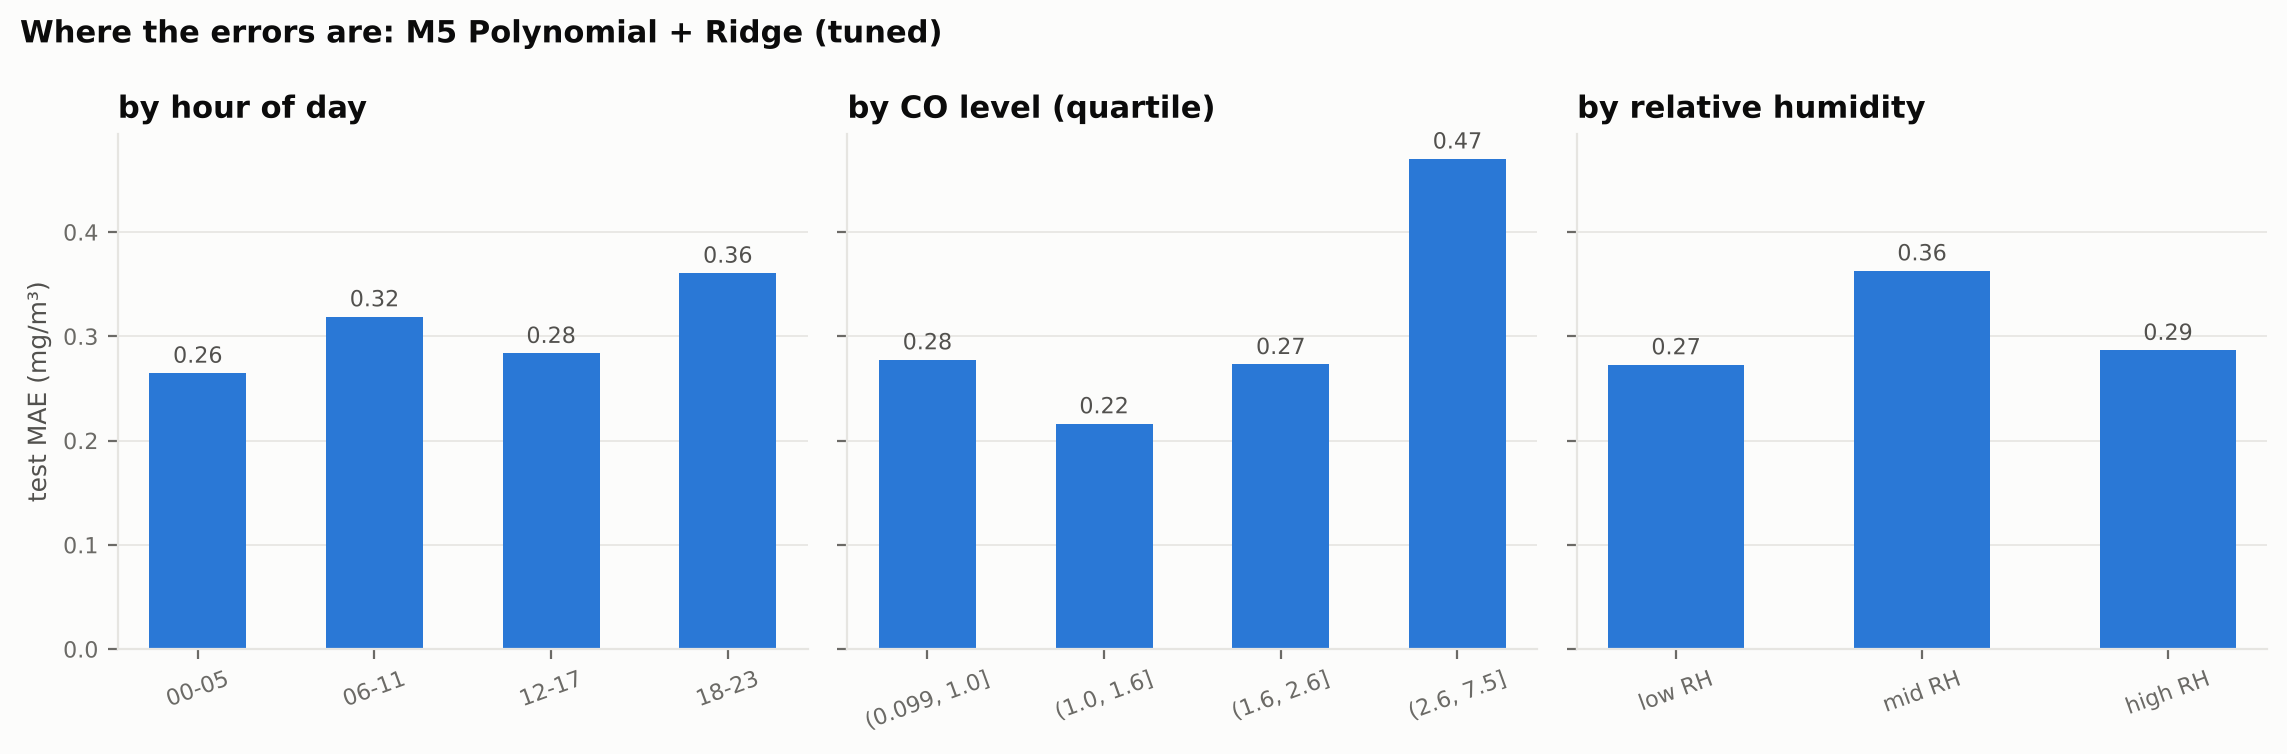

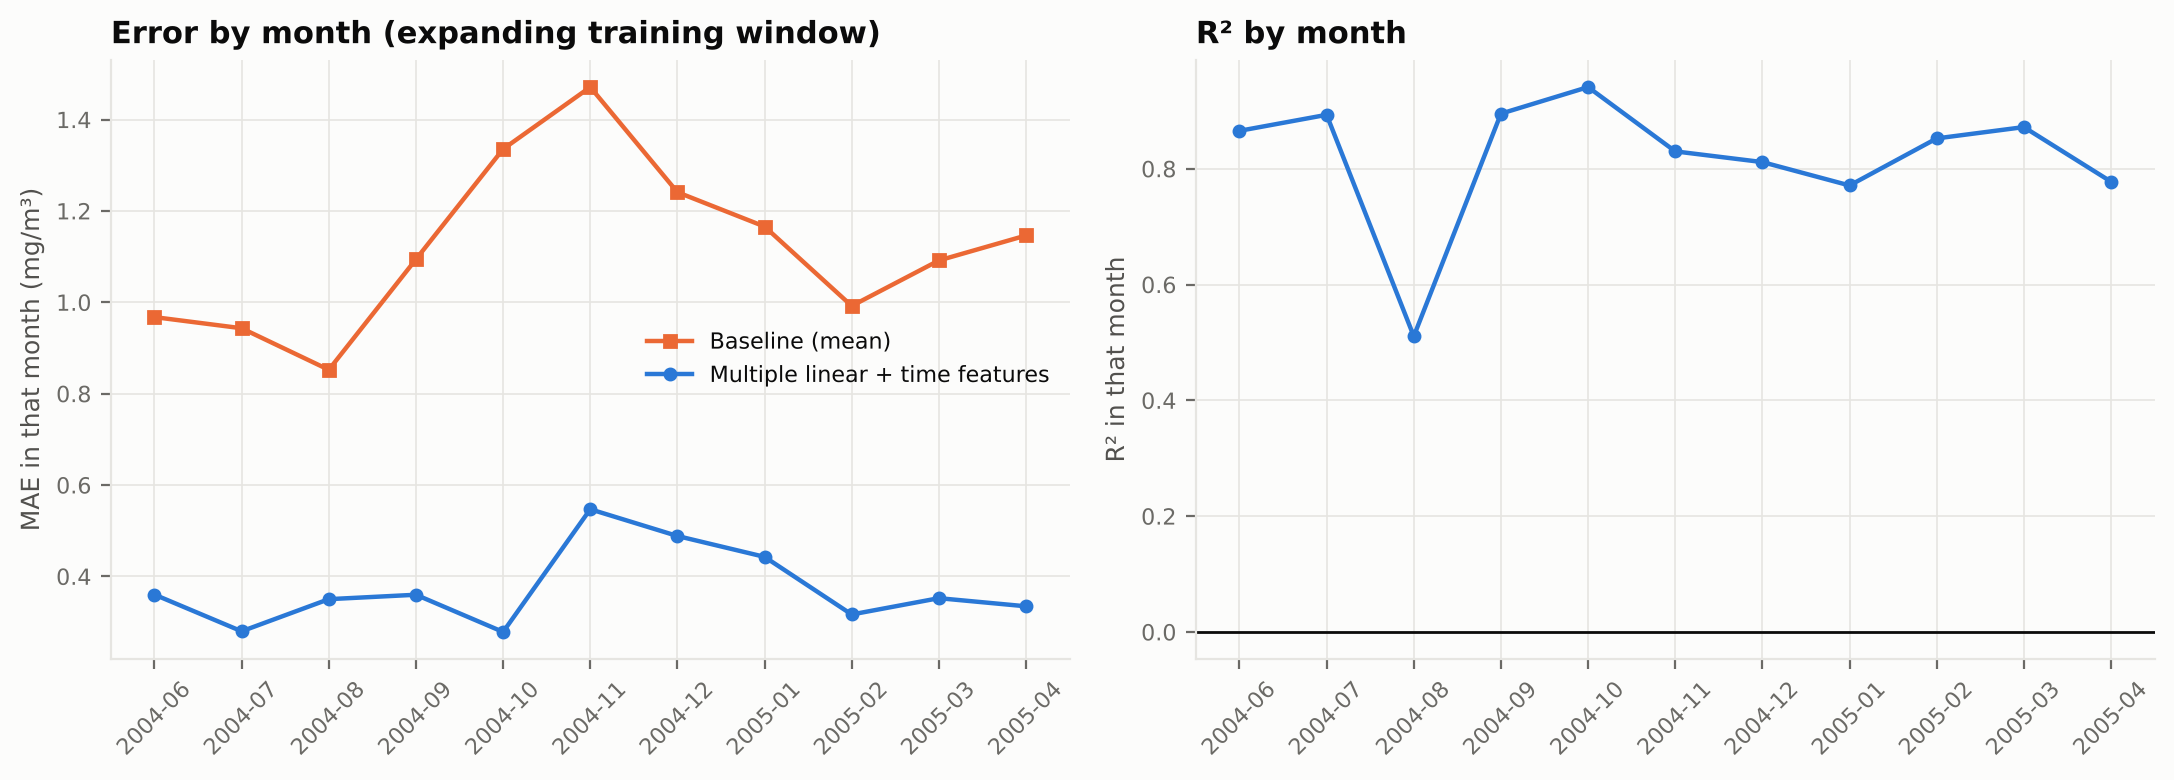

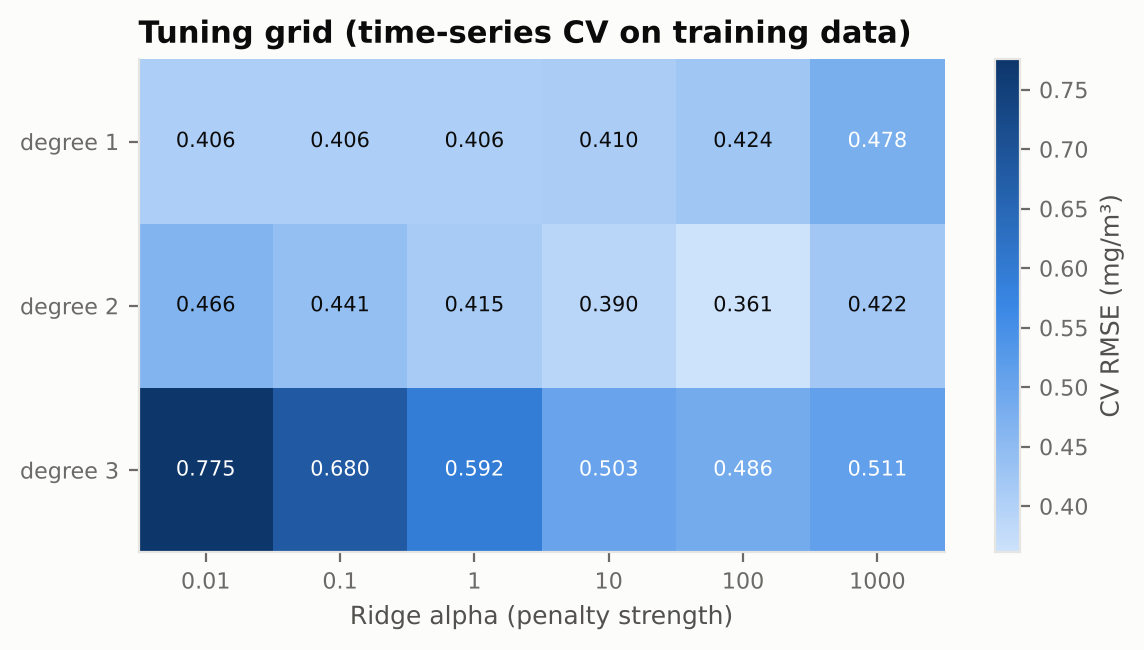

       day  hours  mean_error  mean_actual_CO  mean_pred_CO  mean_T  mean_RH
2005-03-12     20       0.980           0.740         1.720  13.765   48.940
2005-03-13     18       0.973           0.867         1.840  14.917   49.361
2005-02-26     24      -0.897           2.342         1.445   6.604   56.796
2005-03-11     22       0.892           1.623         2.514  11.364   44.241
2005-02-02     24      -0.518           3.350         2.832   7.612   43.938
2005-02-27     23      -0.476           1.761         1.285   6.148   51.291

Mean test error 0.054 mg/m3.  Naive z-test p = 2.8e-06;  after allowing for autocorrelation (lag-1 r = 0.72, n_eff = 243): p = 0.057, 95% CI [-0.003, 0.111]
Random 80/20 split vs chronological 80/20 split (same model): {'random_split': {'MAE': 0.31577668584184476, 'MSE': 0.19523780794790027, 'RMSE': 0.44185722575046826, 'R2': 0.8997942303562629, 'bias': 0.016216276861217377}, 'chronological_split': {'MAE': 0.3520721923312519, 'MSE': 0.23288539804726355, 'R

In [9]:
for f in ["res_02_pred_vs_actual", "res_03_residuals_time", "res_04_error_breakdown", "res_05_drift_monthly", "res_06_cv_grid"]:
    display(Image(str(C.FIG_DIR / f"{f}.png"), width=700))
print(pd.read_csv(C.TABLE_DIR / "10_days_with_largest_mean_error.csv").to_string(index=False))
b = R["bias_test"]
print("\nMean test error %.3f mg/m3.  Naive z-test p = %.2g;  after allowing for autocorrelation (lag-1 r = %.2f, n_eff = %.0f): p = %.3f, 95%% CI %s"
      % (b["mean_error"], b["naive"]["p_value_two_sided"], b["lag1_autocorr"], b["n_effective"],
         b["adjusted"]["p_value_two_sided"], [round(x, 3) for x in b["adjusted"]["CI95"]]))
print("Random 80/20 split vs chronological 80/20 split (same model):", R["random_vs_chronological_M3"])

## 9. Take-aways and limits
* Every model beats the naive guesser by a wide margin; adding the other sensors and temperature/humidity matters far more than any fancy model.
* Hour-of-day features add almost nothing once the sensors are in the model.
* Errors cluster in multi-day episodes and at high CO; a time-ordered split gives a more pessimistic (honest) score than a random split.
* One year, one site, one device: nothing here proves the calibration transfers elsewhere. See the report for the full list of limitations.